<center><h1>Rohith_Sathiya_HW4</h1></center>

Name: Rohith Sathiya
<br>Github Username: Rohith-s9401
<br>USC ID: 7480930295

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### 1.1(a) Obtain Data

Package imports

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import bootstrap
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_curve, confusion_matrix, roc_auc_score, auc
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_selection import RFECV
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.naive_bayes import GaussianNB
from sklearn.utils import resample
from sklearn.naive_bayes import MultinomialNB

import warnings
warnings.filterwarnings('ignore')

In [2]:
FILEPATH = "Data/AReM/"
time_series_columns = ['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']
all_features = ['min', 'max', 'mean', '50%', 'std', '25%', '75%']
time_series_features = ['min', 'max', 'mean', 'median', 'standard deviation', '1st quartile', '3rd quartile' ]
feature_dict = {'50%': 'median', '25%': '1st quart', '75%': '3rd quart', 'std': 'standard deviation', 'min': 'min', 'max': 'max', 'mean': 'mean'}
classes_dict = {'bending1': 0, 'bending2': 1, 'cycling': 2, 'lying': 3, 'sitting': 4, 'standing': 5, 'walking': 6}
rev_classes_dict = {0: 'bending1', 1: 'bending2', 2: 'cycling', 3: 'lying', 4: 'sitting', 5: 'standing', 6: 'walking'}
binary_class_dict = {1: 'bending', 0: 'non-bending'}

In [3]:
files = {}
for folder in os.listdir(FILEPATH):
    if folder == '.DS_Store': continue
    if 'pdf' in folder:
            continue
    for file in os.listdir(FILEPATH + folder):
        key = FILEPATH + folder + '/' + file
        files[key] = pd.read_csv(key, skiprows = 4, usecols = [0, 1, 2, 3, 4, 5, 6])
        del files[key][files[key].columns[0]]

### 1 (b) Test and Train Data

In [4]:
train_data_map = {}
test_data_map = {}
for folder in os.listdir(FILEPATH):
    folder_path = os.path.join(FILEPATH, folder)
    if not os.path.isdir(folder_path):
        continue
    for file in os.listdir(folder_path):
        if not file.lower().endswith('.csv'):
            continue
        file_name = os.path.join(folder_path, file)
        data = files.get(file_name)
        if data is None:
            data = pd.read_csv(file_name, skiprows=4, usecols=range(7))
            data = data.drop(columns=data.columns[0])
            files[file_name] = data
        if folder in ['bending1', 'bending2']:
            if file in ['dataset1.csv', 'dataset2.csv']:
                test_data_map[file_name] = data
            else:
                train_data_map[file_name] = data
        else:
            if file in ['dataset1.csv', 'dataset2.csv', 'dataset3.csv']:
                test_data_map[file_name] = data
            else:
                train_data_map[file_name] = data

print("Total Train Dataset Files: ", len(train_data_map))
print("Total Test Dataset Files: ", len(test_data_map))

Total Train Dataset Files:  69
Total Test Dataset Files:  19


In [5]:
def train_test_split(file_path):
    
    df_train = pd.DataFrame()
    df_test = pd.DataFrame()
    
    folders = os.listdir(file_path)

    for folder in folders:
        if 'pdf' in folder:
            continue
        path = os.path.join(file_path, folder)
        files = os.listdir(path)

        if folder == 'bending1' or folder == 'bending2':
            for file in files:
                data = pd.read_csv(os.path.join(file_path, folder, file), skiprows=4, usecols=range(7))
                if file == 'dataset1.csv' or file == 'dataset2.csv':
                    df_test = pd.concat([df_test, data], ignore_index = True)
                else:
                    df_train = pd.concat([df_train, data], ignore_index = True)
                
        else:
            for file in files:
                data = pd.read_csv(os.path.join(file_path, folder, file), skiprows=4 ,usecols=range(7))
                if file == 'dataset1.csv' or file == 'dataset2.csv' or file == 'dataset3.csv':
                    df_test = pd.concat([df_test, data], ignore_index = True)
                else:
                    df_train = pd.concat([df_train, data], ignore_index = True)
    
    print('Train shape: ', df_train.shape)
    print('Test shape: ', df_test.shape)
    return df_train, df_test

In [6]:
FILEPATH = "Data/AReM"
df_train, df_test = train_test_split(FILEPATH)
df_train.head()

Train shape:  (33119, 7)
Test shape:  (9120, 7)


,# Columns: time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0,42.00,0.71,21.25,0.43,30.00,0.00
1,250,41.50,0.50,20.25,1.48,31.25,1.09
2,500,41.50,0.50,14.25,1.92,33.00,0.00
3,750,40.75,0.83,15.75,0.43,33.00,0.00
4,1000,40.00,0.71,20.00,2.74,32.75,0.43


### 1 c) feature Extraction

#### 1.c) i. Research

1. Maximum - Maximum of a time series data values.
2. Minimum - Minimum of a time series data values.
3. Mean - Arithmetic mean of the data.
4. Median - The value of 50th percentile of the time series data.
5. Standard deviation - Measure of variability of data values.
6. First quartile - The value of 25th percentile of the time series data.
7. Third quartile - The value of 75th percentile of the time series data.
8. Interquartile Range - The difference between 75th and 25th percentiles of the time serives values.
9. Cross-Correlations - Measures the similarity between two time series by computing the correlation between them at different lags.
10. Auto-correlations - Measure of a correlation between a time series and a lagged version of itself.
11. Skewness - Measure of asymmetry of the distribution of data.
12. Orders of the autoregressive (AR), integrated (I) and moving average (MA) part of an estimated ARIMA model

#### 1.c) ii. Extraction

In [7]:
def get_data(file_path):
    
    folders = os.listdir(file_path)
    data = []
    
    for folder in folders:
        if 'pdf' in folder:
            continue
        path = os.path.join(file_path, folder)
        files = os.listdir(path)
        
        for file in files:
            data.append(pd.read_csv(os.path.join(path, file), skiprows=4 ,usecols=range(7)))
                
    return data

In [8]:
time_series_strings = ['min', 'max', 'mean', 'median', 'standard deviation', '1st quartile', '3rd quartile' ]
columns = []
for i in range (1,7):
    columns.append([a+str(i) for a in time_series_strings])
columns = [item for sublist in columns for item in sublist]
df = pd.DataFrame(columns = columns)

data = get_data(FILEPATH)
for d in data:
    summary = d.describe()
    row = []
    for i in range(1,7):
        row.append(summary.iloc[3,i])
        row.append(summary.iloc[7,i])
        row.append(summary.iloc[1,i])
        row.append(summary.iloc[5,i])
        row.append(summary.iloc[2,i])
        row.append(summary.iloc[4,i])
        row.append(summary.iloc[6,i])
    df.loc[len(df)] = row
df.index = df.index + 1
df

,min1,max1,mean1,median1,standard deviation1,1st quartile1,3rd quartile1,min2,max2,mean2,...,standard deviation5,1st quartile5,3rd quartile5,min6,max6,mean6,median6,standard deviation6,1st quartile6,3rd quartile6
1,37.25,45.00,40.624792,40.500,1.476967,39.25,42.0000,0.0,1.30,0.358604,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.430,0.582915,0.00,1.3000
2,38.00,45.67,42.812812,42.500,1.435550,42.00,43.6700,0.0,1.22,0.372437,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.430,0.601010,0.00,1.3000
3,35.00,47.40,43.954500,44.330,1.558835,43.00,45.0000,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.430,0.513506,0.00,0.9400
4,33.00,47.75,42.179812,43.500,3.670666,39.15,45.0000,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.500,0.524317,0.00,1.0000
5,33.00,45.75,41.678063,41.750,2.243490,41.33,42.7500,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.430,0.389164,0.00,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,20.75,46.25,34.763333,35.290,4.742208,31.67,38.2500,0.0,12.68,4.223792,...,3.174681,14.2500,18.33,0.0,9.39,3.288271,3.270,1.647528,2.05,4.3050
85,21.50,51.00,34.935812,35.500,4.645944,32.00,38.0625,0.0,12.21,4.115750,...,3.192058,14.2375,18.25,0.0,10.21,3.280021,3.015,1.700918,2.12,4.5000
86,18.33,47.67,34.333042,34.750,4.948770,31.25,38.0000,0.0,12.48,4.396958,...,3.000493,13.7500,18.00,0.0,8.01,3.261583,2.980,1.617290,2.05,4.3200
87,18.33,45.75,34.599875,35.125,4.731790,31.50,38.0000,0.0,15.37,4.398833,...,2.905688,14.0000,18.25,0.0,8.86,3.289542,3.015,1.680170,2.12,4.2600


In [9]:
df.shape

(88, 42)

#### 1.c) iii. Standard Deviation

In [10]:
df.describe().loc[['std']].T

,std
min1,9.569975
max1,4.394362
mean1,5.335718
median1,5.440054
standard deviation1,1.772153
1st quartile1,6.153590
3rd quartile1,5.138925
min2,0.000000
max2,5.062729
mean2,1.574164


In [11]:
confidence_intervals = pd.DataFrame()
for i in range(len(df.columns)):
    sample_data = (df.iloc[:, i],)
    res = bootstrap(sample_data, np.std, confidence_level = 0.9, random_state = 1, method = 'percentile')
    temp = pd.DataFrame({'Feature': df.columns[i], 'Lower Bound': res.confidence_interval.low, 'Upper Bound': res.confidence_interval.high}, index=[i+1])
    confidence_intervals = pd.concat([confidence_intervals, temp], ignore_index = True)
confidence_intervals

,Feature,Lower Bound,Upper Bound
0,min1,8.208212,10.718897
1,max1,3.302124,5.277910
2,mean1,4.683108,5.864954
3,median1,4.774987,5.983471
4,standard deviation1,1.561586,1.930514
5,1st quartile1,5.548767,6.619312
6,3rd quartile1,4.299096,5.819304
7,min2,0.000000,0.000000
8,max2,4.598099,5.372570
9,mean2,1.388105,1.698038


#### iv. Select Features

From the above summary data, according to me, the 3 most important time domain features:

1. Mean: Describes the central level of the time series using all observations. However, it can be affected by extreme values.
2. Median: Since the data has too many outliers which can make the data skewed, median could be a good feature to have which is not affected much by outliers.
3. Standard deviation: Measures the variability or dispersion of the time series around its mean. It gives an insight into the underlying data distribution.

Together, these features describe both the location and variability of each time series.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

In [12]:
def get_class_from_key(key, is_binary):
    activity = os.path.basename(
        os.path.dirname(os.path.normpath(key))
    )

    if is_binary:
        return 1 if activity in ['bending1', 'bending2'] else 0

    return classes_dict[activity] 

In [13]:
def get_features(selected_time_series, selected_feature_names, split):
    ans = []
    for split_no in range(split):
        for time_series_col in selected_time_series:
            for feature in selected_feature_names:
                ans += [time_series_col + '_' + feature_dict[feature] + str(split_no + 1)]
    ans += ['type']
    return ans

In [14]:
def get_data_modified(train_data_map, split, headers, time_series, selected_features, is_binary=True):

    train_df = []
    for k, v in train_data_map.items():
        splits = np.array_split(v, split)
        temp = []
        for s in splits:
            stat = s.describe()
            for series in time_series:
                for feature in selected_features:
                    temp.append(stat[series][feature])

        temp.append(get_class_from_key(k, is_binary))
        train_df.append(temp)
        
    train_df = pd.DataFrame(train_df, columns = headers)
    return train_df

type
0    60
1     9
Name: count, dtype: int64


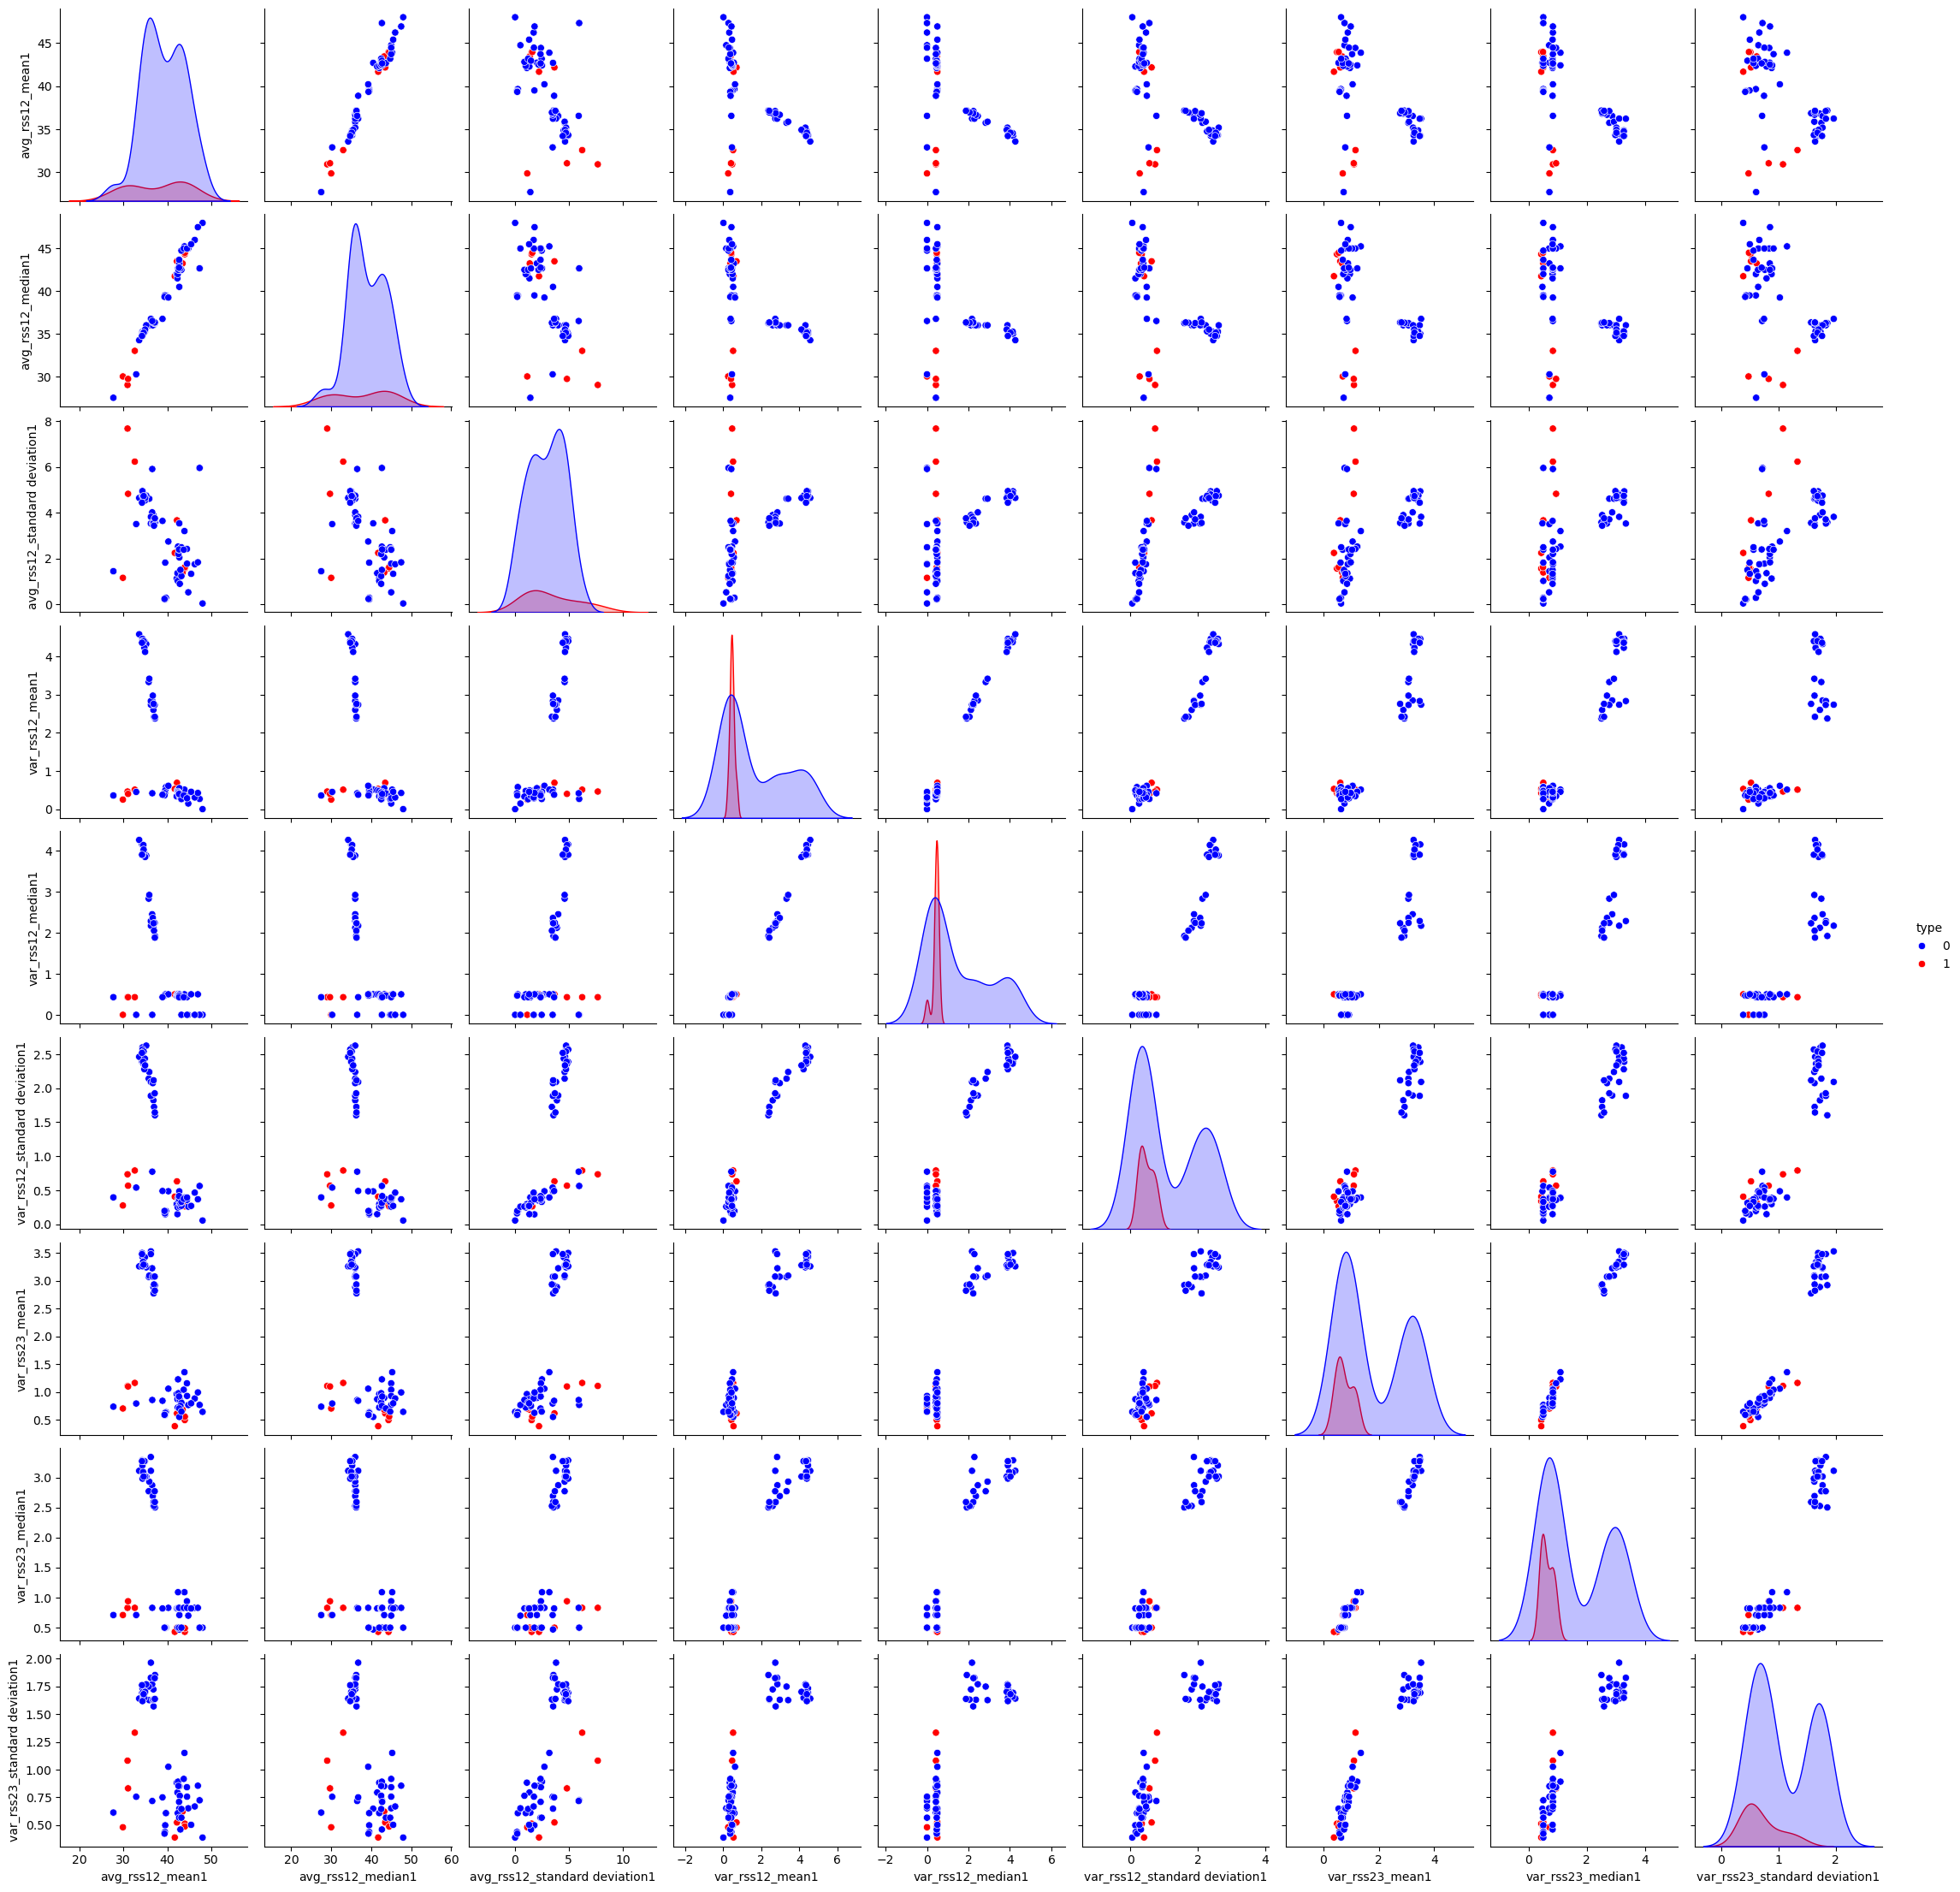

In [15]:
selected_time_series = ['avg_rss12', 'var_rss12', 'var_rss23']
selected_features = ['mean', '50%', 'std']
headers = get_features(selected_time_series, selected_features, 1)
train_data_df = get_data_modified(train_data_map, 1, headers, selected_time_series, selected_features)
print(train_data_df['type'].value_counts())
sns.pairplot(data=train_data_df, hue='type', hue_order=[0, 1], palette={0: 'blue', 1: 'red'})
plt.show()

#### 2.1.2 ii) Splitted Plots

type
0    60
1     9
Name: count, dtype: int64


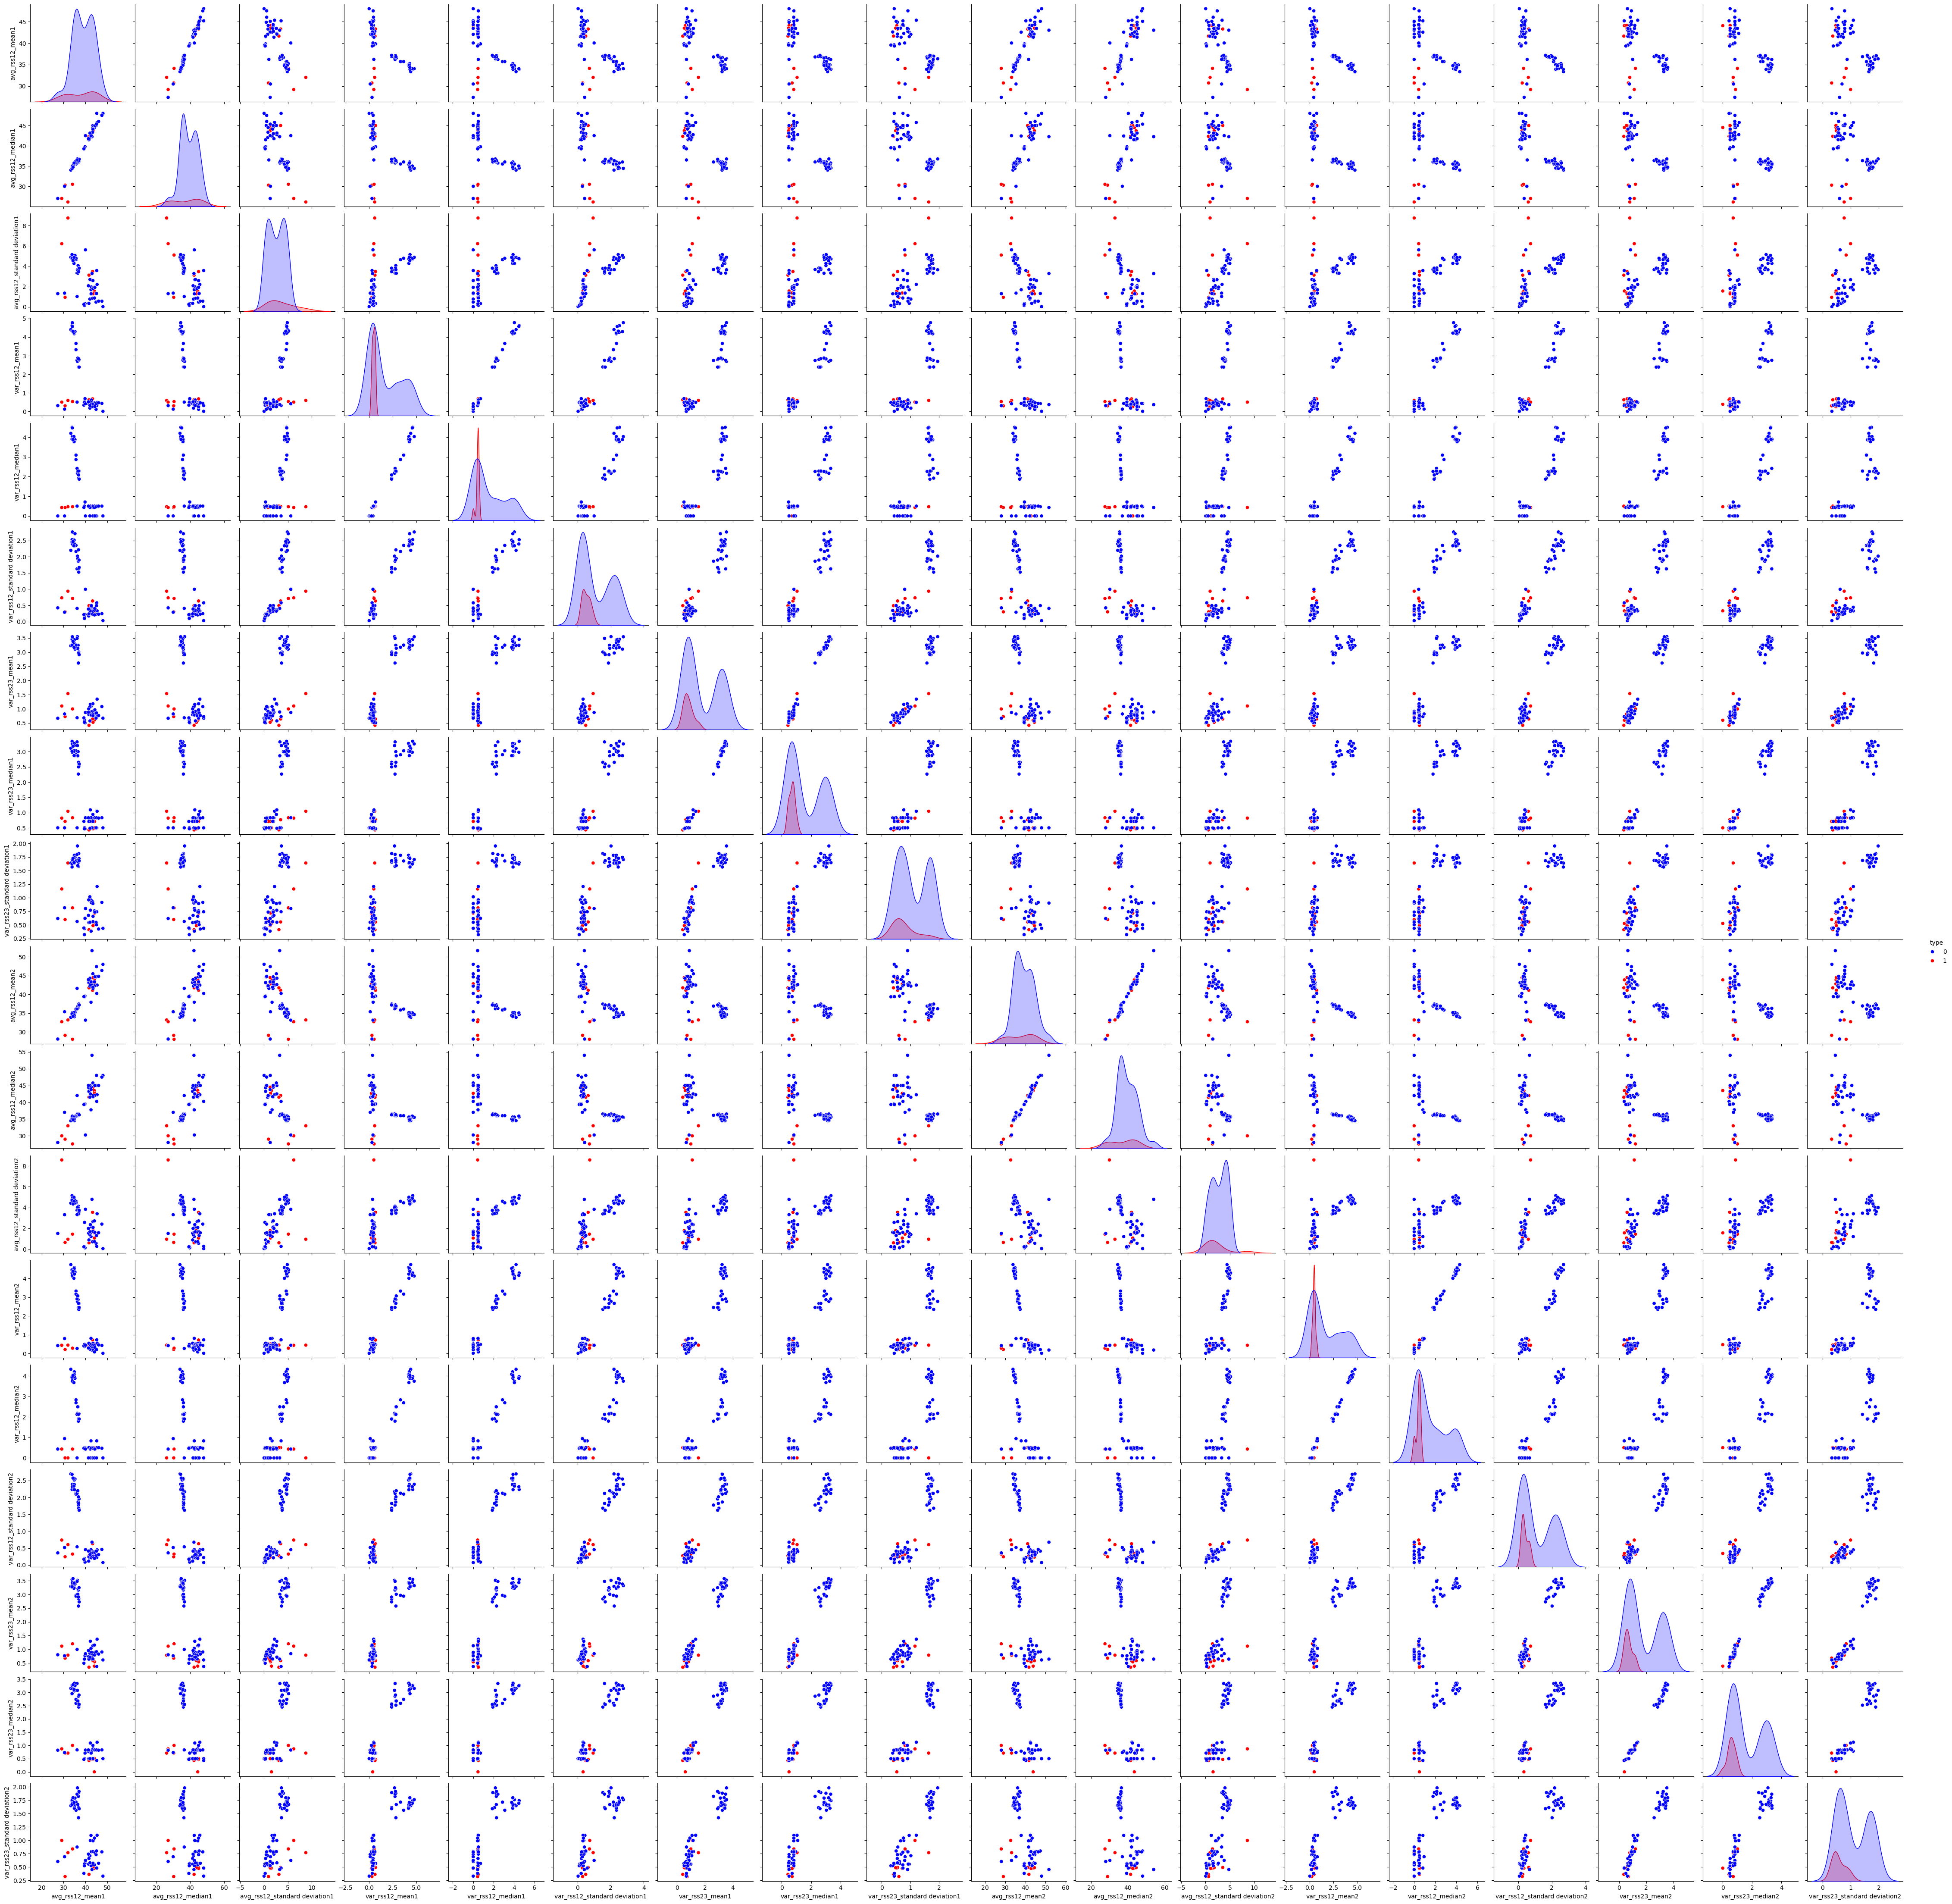

In [16]:
selected_time_series = ['avg_rss12', 'var_rss12', 'var_rss23']
selected_features = ['mean', '50%', 'std']
headers = get_features(selected_time_series, selected_features, 2) 
train_data_df = get_data_modified(train_data_map, 2, headers, selected_time_series, selected_features)
print(train_data_df['type'].value_counts())
sns.pairplot(data=train_data_df, hue='type', hue_order=[0, 1], palette={0: 'blue', 1: 'red'})
plt.show()

#### 2.1.3 Observation:
* In the initial oberservation, we don't notice much of a difference between both the plots. 

#### 2.1.4 iii Time Series Segments

In [17]:
def oversample_imbalance_class(train_df):
    
    total0 = train_df.loc[train_df['type'] == 0].shape[0]
    total1 = train_df.loc[train_df['type'] == 1].shape[0]
    minor_label, major_label = (1, 0) if total0 > total1 else (0, 1)
        
    minor_ds = train_df[train_df['type'] == minor_label]
    major_ds = train_df[train_df['type'] == major_label]
    
    minor_ds = resample(minor_ds, replace = True, random_state = 60, n_samples = max(total0, total1))
    train_df = pd.concat([major_ds, minor_ds])
    return train_df

In [18]:
def logistic_regression(train_data_map, test_data_map, split, cv_fold, time_series = time_series_columns, features = all_features, oversampling = False):

    # get features and data
    headers = get_features(time_series, features, split)
    train_df = get_data_modified(train_data_map, split, headers, time_series, features)    
    
    # oversampling to prevent imbalance
    if oversampling: 
        train_df = oversample_imbalance_class(train_df)
    
    # spliting data to train X and label Y
    trainX = train_df.iloc[:, :-1]
    trainY = train_df.iloc[:, -1]

    # main model
    validator = StratifiedKFold(n_splits = cv_fold, shuffle = True, random_state = 69)
    model = LogisticRegression(penalty = None, solver = 'lbfgs', max_iter = 100)
    selector = RFECV(estimator = model, cv = validator, scoring = 'accuracy')
    selector.fit(trainX, trainY)
    
    test_accuracy = selector.cv_results_['mean_test_score'].max()
    
    return model, selector, round(test_accuracy, 5), round(1 - test_accuracy, 5)


In [21]:
selected_features = ['mean', '50%', 'std']
cv_fold = 5
split_range = 20
LR_result = {'Split': [], 'No. of Features': [], 'Test Score': [], 'Test Error': []}
for split in range(1, split_range + 1):
    model, selector, score, error = logistic_regression(train_data_map, test_data_map, split, cv_fold, features = selected_features)
    LR_result['Split'].append(split)
    LR_result['No. of Features'].append(selector.n_features_)
    LR_result['Test Score'].append(score)
    LR_result['Test Error'].append(error)

LR_result = pd.DataFrame(LR_result)
LR_result

,Split,No. of Features,Test Score,Test Error
0,1,7,0.95714,0.04286
1,2,6,0.95714,0.04286
2,3,4,0.98571,0.01429
3,4,4,0.95714,0.04286
4,5,2,0.98571,0.01429
5,6,2,0.98571,0.01429
6,7,5,0.95714,0.04286
7,8,2,0.97143,0.02857
8,9,3,0.97143,0.02857
9,10,1,0.97143,0.02857


#### 2.1.5 Observations:
* We can observe from the above table that best (l, p) pair is (3, 4).
* The purpose of cross-validation is to estimate the error on test data. If we perform RFE before Cross Validation, there might be important predictors which will be discarded. So the **correct way is to perform RFE along with Cross Validation**

#### 2.1.6 iv. Confusion Matrix

In [22]:
def selected_features_from_logistic_regression(features, selector):
    selected_features = []
    for i, feature in enumerate(features):
        if selector.support_[i]:
            selected_features.append(feature)
    return selected_features

In [23]:
selected_features = ['mean', '50%', 'std']

best_idx = LR_result['Test Score'].argmax()
print("Best pair: ({}, {}) \n".format(LR_result['Split'][best_idx], LR_result['No. of Features'][best_idx]))

split = LR_result['Test Score'].argmax() + 1
cv_fold = 5
headers = get_features(time_series_columns, selected_features, split)
model_lr, selector, score, error = logistic_regression(train_data_map, test_data_map, split, cv_fold, features = selected_features)

RFE_selected_features = selected_features_from_logistic_regression(headers[:-1], selector)
print("RFE selected features: ", RFE_selected_features)

Best pair: (3, 4) 

RFE selected features:  ['avg_rss13_median1', 'avg_rss23_mean1', 'avg_rss23_median1', 'avg_rss12_mean3']


In [24]:
headers = get_features(time_series_columns, selected_features, split)
train_df = get_data_modified(train_data_map, split, headers, time_series_columns, selected_features)  
trainX, trainY = train_df.iloc[:, :-1], train_df.iloc[:, -1]
df_temp = trainX.loc[:, RFE_selected_features]
const_val = sm.add_constant(df_temp.to_numpy(dtype = float))
model = sm.Logit(trainY.to_numpy(dtype = float), const_val)
summary = model.fit(method = 'bfgs').summary()
print(summary)

Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 26
         Function evaluations: 29
         Gradient evaluations: 29
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       64
Method:                           MLE   Df Model:                            4
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                   1.000
Time:                        10:14:21   Log-Likelihood:            -1.2019e-05
converged:                       True   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 6.909e-11
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.1355   3.64e+04  -5.8

#### 2.1.7 Observations: 
* As per the above p-value analysis and note underneath, we can say that the data is completely seperated.

In [25]:
def plot_roc(true_y, pred_y_prob, model):
    
    _, axes = plt.subplots(figsize = (8, 6))
    axes.set_title("ROC curves")
    for i, class_ in enumerate(model.classes_):
        y_pred = pred_y_prob[:, i]
        fpr, tpr, thresholds = roc_curve(true_y, y_pred, pos_label = class_)
        roc_auc = auc(fpr, tpr)
        if (len(model.classes_) == 2):
            axes.plot(fpr, tpr, label = "Class: {}; AUC: {}".format(binary_class_dict[class_], round(roc_auc, 4)))
        else: 
            axes.plot(fpr, tpr, label = "Class: {}; AUC: {}".format(rev_classes_dict[class_], round(roc_auc, 4)))
    
    axes.plot([0, 1], [0, 1], "--")
    axes.set_xlabel("False Positive Rate")
    axes.set_ylabel("True Positive Rate")
    axes.legend()
    plt.show()

def get_cm_roc(model, trainX, trainY, selected_features, test_data = False):
    
    if not test_data:
        model.fit(trainX.loc[:, selected_features], trainY.to_numpy(dtype = "int"))
        
    pred_y = model.predict(trainX.loc[:, selected_features])
    pred_y_prob = model.predict_proba(trainX.loc[:, selected_features])
    pred_y = pred_y.round()
    true_y = trainY.to_numpy(dtype = float)
    t_score = model.score(trainX.loc[:, selected_features], trainY.to_numpy(dtype = "int"))
    print("Accuracy: {}".format(t_score))
    print("Confusion Matrix")
    print(confusion_matrix(true_y, pred_y))
    plot_roc(true_y, pred_y_prob, model)

Accuracy: 1.0
Confusion Matrix
[[60  0]
 [ 0  9]]


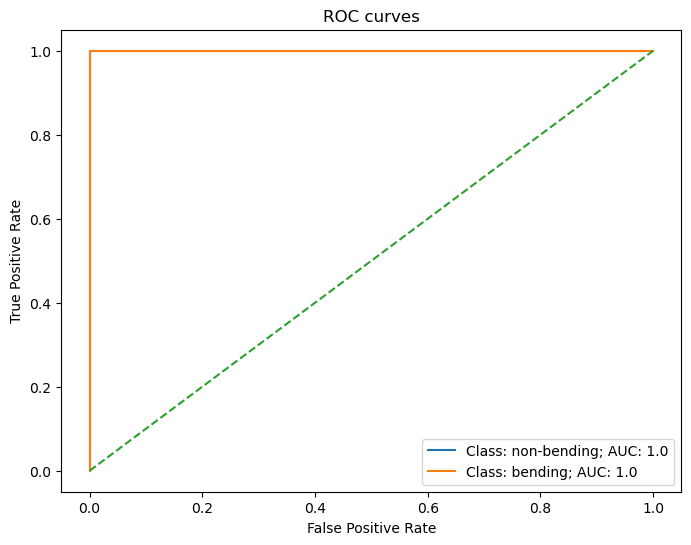

In [26]:
get_cm_roc(model_lr, trainX, trainY, RFE_selected_features)

#### 2.1.8 v. Test Classifier

In [27]:
idx = LR_result['Test Score'].argmax()
split = idx + 1
headers = get_features(time_series_columns, selected_features, split)
test_df = get_data_modified(test_data_map, split, headers, time_series_columns, selected_features)  
testX, testY = test_df.iloc[:, :-1], test_df.iloc[:, -1]
test_df

,avg_rss12_mean1,avg_rss12_median1,avg_rss12_standard deviation1,var_rss12_mean1,var_rss12_median1,var_rss12_standard deviation1,avg_rss13_mean1,avg_rss13_median1,avg_rss13_standard deviation1,var_rss13_mean1,...,var_rss13_mean3,var_rss13_median3,var_rss13_standard deviation3,avg_rss23_mean3,avg_rss23_median3,avg_rss23_standard deviation3,var_rss23_mean3,var_rss23_median3,var_rss23_standard deviation3,type
0,41.362563,42.000,0.954146,0.256125,0.000,0.292648,18.327063,18.750,3.587579,0.581188,...,1.006312,0.710,1.051172,33.048812,32.625,2.879596,0.508875,0.430,0.510427,1
1,42.921750,43.000,0.612032,0.468438,0.500,0.202144,19.926937,20.500,3.187207,0.834688,...,1.077812,0.830,1.112117,31.673500,31.500,1.788925,0.402375,0.430,0.494225,1
2,22.609937,23.750,3.095682,0.871187,0.500,1.095289,19.152000,19.500,3.515329,0.603437,...,0.802562,0.470,1.006655,20.327688,20.585,2.349026,0.834562,0.710,0.734751,1
3,28.792875,29.250,1.171331,0.211625,0.000,0.236587,19.547875,20.290,2.735130,0.613125,...,1.114875,0.830,1.141619,16.303937,14.875,7.523331,1.715125,1.300,1.370512,1
4,36.794750,35.875,3.722530,2.459812,2.085,1.540435,17.569313,17.585,3.378548,3.063813,...,2.622812,2.450,1.488445,19.690750,20.250,2.614008,2.757937,2.360,1.885510,0
5,37.521813,37.000,3.055485,2.156500,1.790,1.517329,16.079687,16.290,2.905212,3.281687,...,2.830062,2.650,1.531474,19.839250,20.330,2.586191,2.668250,2.175,1.708308,0
6,38.028875,36.750,3.459354,2.005125,1.300,2.087251,16.356875,16.790,4.161431,2.698938,...,3.019625,2.870,1.704512,15.377875,15.625,3.240991,3.578813,3.350,1.884558,0
7,27.788063,27.250,1.141923,0.234313,0.000,0.357117,6.048563,6.710,2.413133,0.846000,...,0.804500,0.500,0.871129,7.138563,6.710,4.695814,0.779438,0.820,0.597059,0
8,36.541562,30.000,9.006695,0.291875,0.000,0.547322,6.689250,6.290,2.632085,0.904062,...,0.291875,0.430,0.256241,1.894750,2.000,0.789324,0.434250,0.470,0.402082,0
9,48.000000,48.000,0.000000,0.000000,0.000,0.000000,5.611250,6.000,1.513654,0.397187,...,0.410750,0.430,0.453793,10.496062,10.415,0.791692,0.671625,0.730,0.315375,0


Accuracy: 0.9473684210526315
Confusion Matrix
[[14  1]
 [ 0  4]]


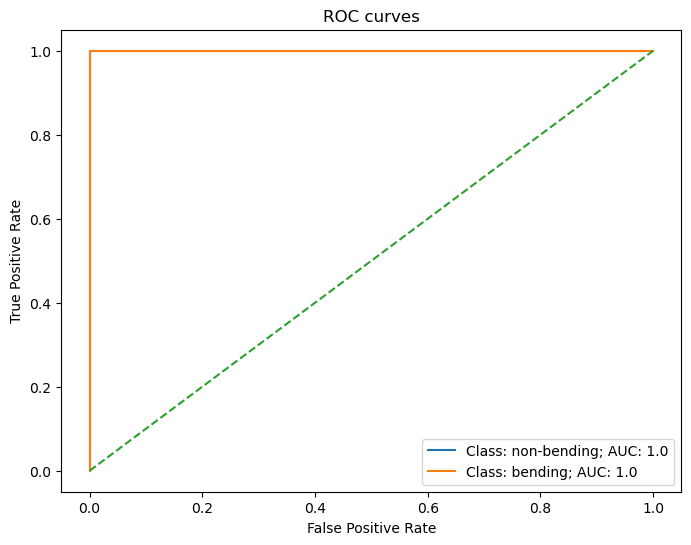

In [28]:
get_cm_roc(model_lr, testX, testY, RFE_selected_features, test_data = True)

#### 2.1.9 Observation:
* The selected model achieved 0.98571 cross-validation accuracy and 0.94737 test accuracy. The test accuracy is slightly lower than the cross-validation estimate.

#### 2.1.10 vi.Separation

* From the p-value analysis using statmodel suggests that there is complete separation. In this case, the Maximum Likelihood Estimator (MLE) doesn't exist and the parameters are not identified.
* Because of this, it is possible that the well-separation of the classes is cauisng the instability in calculation of the regression parameters.

#### 2.1.11 vii.Imbalance

* Yes, the data has an imbalance in it. **Class 0 points are 60. Whereas Class 1 points are just 9.**

In [29]:
selected_features = ['mean', '50%', 'std']
cv_fold = 5
split_range = 20
LR_Oversampling_result = {'Split': [], 'No. of Features': [], 'Test Score': [], 'Test Error': []}
for split in range(1, split_range + 1):
    model, selector, score, error = logistic_regression(train_data_map, test_data_map, split, cv_fold, oversampling = True, features = selected_features)
    LR_Oversampling_result['Split'].append(split)
    LR_Oversampling_result['No. of Features'].append(selector.n_features_)
    LR_Oversampling_result['Test Score'].append(score)
    LR_Oversampling_result['Test Error'].append(error)

LR_Oversampling_result = pd.DataFrame(LR_Oversampling_result)
LR_Oversampling_result

,Split,No. of Features,Test Score,Test Error
0,1,6,0.98333,0.01667
1,2,4,0.97500,0.02500
2,3,5,0.98333,0.01667
3,4,4,0.98333,0.01667
4,5,3,0.98333,0.01667
5,6,2,0.99167,0.00833
6,7,6,0.98333,0.01667
7,8,137,0.99167,0.00833
8,9,4,1.00000,0.00000
9,10,18,0.99167,0.00833


In [30]:
selected_features = ['mean', '50%', 'std']

best_idx = LR_Oversampling_result['Test Score'].argmax()
print("Best pair: ({}, {}) \n".format(LR_Oversampling_result['Split'][best_idx], LR_Oversampling_result['No. of Features'][best_idx]))

split = LR_Oversampling_result['Test Score'].argmax() + 1
cv_fold = 5
headers = get_features(time_series_columns, selected_features, split)
model_oversampling_lr, selector, score, error = logistic_regression(train_data_map, test_data_map, split, cv_fold, oversampling = True, features = selected_features)

RFE_selected_features = selected_features_from_logistic_regression(headers[:-1], selector)
print("RFE selected features: ", RFE_selected_features)

Best pair: (9, 4) 

RFE selected features:  ['avg_rss23_median2', 'avg_rss23_mean3', 'avg_rss12_mean6', 'avg_rss13_median8']


ROC Curve for train data

Accuracy: 1.0
Confusion Matrix
[[60  0]
 [ 0 60]]


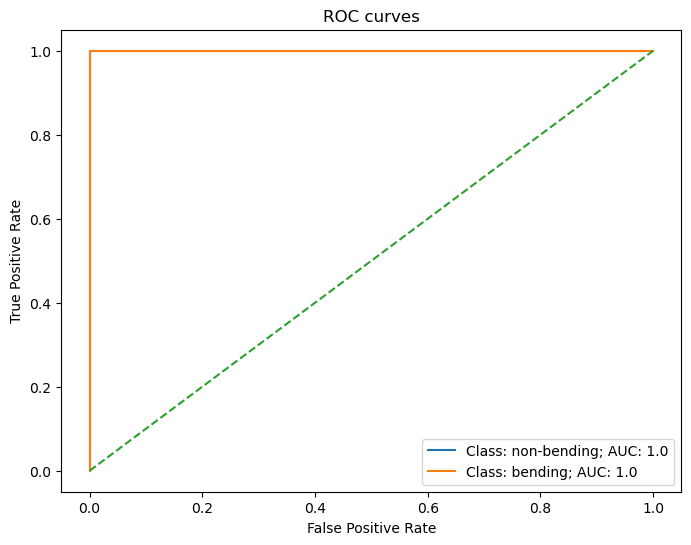

In [31]:
headers = get_features(time_series_columns, selected_features, split)
train_df = get_data_modified(train_data_map, split, headers, time_series_columns, selected_features)  
train_df = oversample_imbalance_class(train_df)
trainX, trainY = train_df.iloc[:, :-1], train_df.iloc[:, -1]
print("ROC Curve for train data\n")
get_cm_roc(model_oversampling_lr, trainX, trainY, RFE_selected_features)

ROC Curve for test data

Accuracy: 0.9473684210526315
Confusion Matrix
[[15  0]
 [ 1  3]]


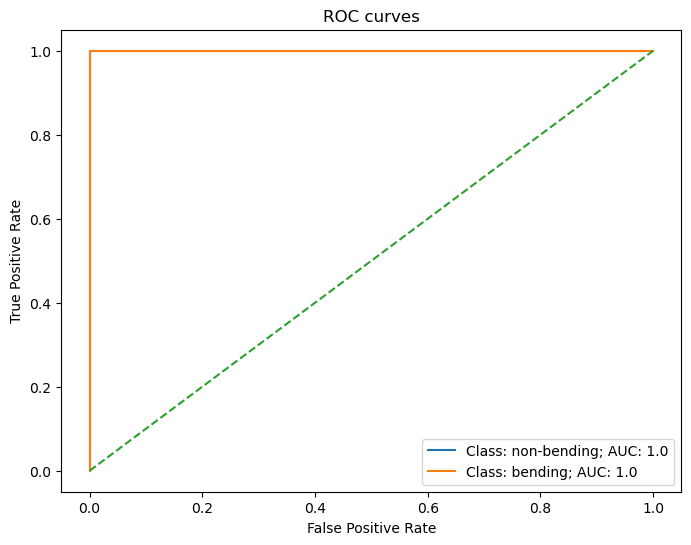

In [32]:
headers = get_features(time_series_columns, selected_features, split)
test_df = get_data_modified(test_data_map, split, headers, time_series_columns, selected_features)  
testX, testY = test_df.iloc[:, :-1], test_df.iloc[:, -1]
test_df
print("ROC Curve for test data\n")
get_cm_roc(
    model_oversampling_lr,
    testX,
    testY,
    RFE_selected_features,
    test_data=True
)

### 2.2 (b) Binary Classification Using L1-penalized logistic regression

#### 2.2 i. Time Series Segments

In [33]:
def get_index_best_c(model, find_C_in_dict):
    for i, c in enumerate(model.Cs_):
        if (c == find_C_in_dict): 
            return i

def logistic_regression_classification(train_data_map, test_data_map, split, time_series = time_series_columns, features = all_features, 
                         cv_fold = None, is_plot_roc = False,
                         is_binary = False, is_gaussian = False, is_multinomial_prior = False):
    
    headers = get_features(time_series_columns, features, split)
    train_df = get_data_modified(train_data_map, split, headers, time_series, features, is_binary= is_binary)  
    test_df = get_data_modified(test_data_map, split, headers, time_series, features, is_binary = is_binary) 
        
    # splitting labels from training data
    trainX, trainY = train_df.iloc[:, :-1], train_df.iloc[:, -1]
    testX, testY = test_df.iloc[:, :-1], test_df.iloc[:, -1]
    random_state = 69 if cv_fold != None else None
    
    # main model for binary and multinomial
    if is_binary:
        model = LogisticRegressionCV(penalty = 'l1', max_iter = 100, scoring = 'accuracy',
                                     cv = cv_fold, random_state = random_state, solver = 'liblinear')  
        model.fit(trainX, trainY)
        idx = get_index_best_c(model, model.C_[0])
        train_score = np.mean(model.scores_[1][:, idx])
    elif is_gaussian:
        model = GaussianNB()
        if (is_plot_roc):
            model.fit(trainX, trainY)
        score = cross_val_score(estimator = model,X = trainX, y = trainY, 
                                cv = StratifiedKFold(n_splits = 5, random_state = 0, shuffle = True), 
                                scoring = "accuracy")
        train_score = np.mean(score)
    elif is_multinomial_prior:
        model = MultinomialNB()
        if (is_plot_roc):
            model.fit(trainX, trainY)
        score = cross_val_score(estimator = model,X = trainX, y = trainY, 
                                cv = StratifiedKFold(n_splits = 5, random_state = 0, shuffle = True), 
                                scoring = "accuracy")
        train_score = np.mean(score)
        
    else:
        model = LogisticRegressionCV(penalty = 'l1', max_iter = 100, multi_class = 'multinomial', 
                                     cv = cv_fold, random_state = random_state, solver = 'saga') 
        model.fit(trainX, trainY)
        idx = get_index_best_c(model, model.C_[0])
        score = 0
        for class_ in model.scores_.keys():
            score += np.mean(model.scores_[class_][:, idx])
        train_score = score/len(model.scores_.keys())
    train_error = round((1 - train_score), 4)
    
    # printing results as per the need
    if not is_plot_roc:    
        return [split, train_score, train_error]
    else:
        
        train_predict = model.predict_proba(trainX)
        test_predict = model.predict_proba(testX)
        pred_y = model.predict(testX)
        cm = confusion_matrix(testY, pred_y)
        
        print("Confusion matrix for test data:\n{}".format(cm))
        print("ROC Curve for Train Data")
        plot_roc(trainY, train_predict, model)
        
        print("ROC Curve for Test Data")
        plot_roc(testY, test_predict, model)

In [34]:
selected_features = ['mean', '50%', 'std']
cv_fold, split_range, result = 5, 20, []
max_test_accuracy, best_split = 0, 1

# performing regression for l = 1 to 20
for split in range(1, split_range + 1):
    result.append(logistic_regression_classification(train_data_map, test_data_map, split, cv_fold = cv_fold, is_binary = True, features = selected_features))
    if result[-1][1] > max_test_accuracy:
        max_test_accuracy = result[-1][1]
        best_split = split

result = pd.DataFrame(result, columns = ['Split', 'Train Score', 'Train Error'])
result

,Split,Train Score,Train Error
0,1,0.956044,0.0440
1,2,0.942857,0.0571
2,3,0.957143,0.0429
3,4,0.957143,0.0429
4,5,0.971429,0.0286
5,6,0.957143,0.0429
6,7,0.957143,0.0429
7,8,0.957143,0.0429
8,9,0.957143,0.0429
9,10,0.957143,0.0429


Best model with split = 5, max_test_accuracy = 0.9714285714285715

Confusion matrix for test data:
[[15  0]
 [ 1  3]]
ROC Curve for Train Data


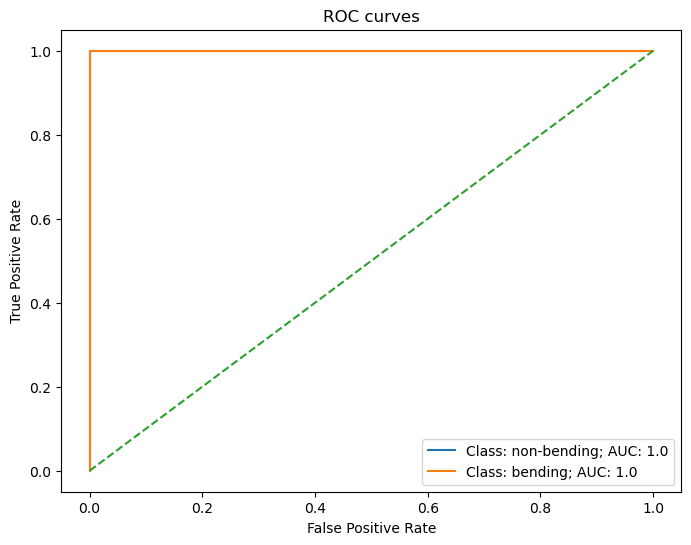

ROC Curve for Test Data


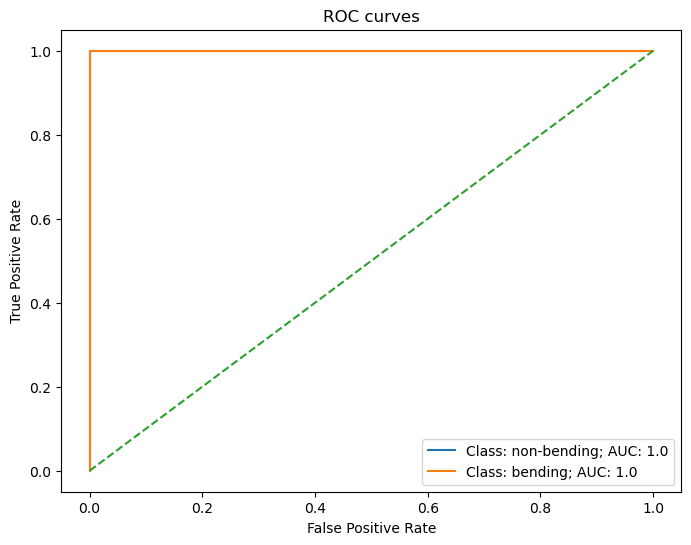

In [35]:
print("Best model with split = {}, max_test_accuracy = {}\n".format(best_split, max_test_accuracy))
logistic_regression_classification(train_data_map, test_data_map, best_split, is_plot_roc = True, is_binary = True, features = selected_features)

#### 2.2.2 ii Comparison

* The RFE model achieved a higher cross-validation accuracy (0.9857) than the L1-penalized model (0.9714). Both models achieved the same test accuracy (0.9474), so their test performance was equal.
* L1 regularization is easier to implement because it performs feature selection through the penalty, without requiring a separate feature-selection step.

### 2.3 (c) Multi-class Classification (The Realistic Case)

#### 2.3.1 i Time Series Segments

In [36]:
selected_features = ['mean', '50%', 'std']
cv_fold, split_range, result = 5, 20, []
max_test_accuracy, best_split = 0, 1

for split in range(1, split_range + 1):
    result.append(logistic_regression_classification(train_data_map, test_data_map, split, cv_fold = cv_fold, features = selected_features))
    if result[-1][1] > max_test_accuracy:
        max_test_accuracy = result[-1][1]
        best_split = split

result = pd.DataFrame(result, columns = ['L', 'Train Score', 'Train Error'])
result

,L,Train Score,Train Error
0,1,0.870330,0.1297
1,2,0.856044,0.1440
2,3,0.812088,0.1879
3,4,0.813187,0.1868
4,5,0.769231,0.2308
5,6,0.783516,0.2165
6,7,0.783516,0.2165
7,8,0.753846,0.2462
8,9,0.753846,0.2462
9,10,0.768132,0.2319


Best model with split = 1, max_test_accuracy = 0.8703296703296701

Confusion matrix for test data:
[[2 0 0 0 0 0 0]
 [1 0 1 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 2 1 0]
 [0 0 0 0 0 3 0]
 [0 0 0 0 0 0 3]]
ROC Curve for Train Data


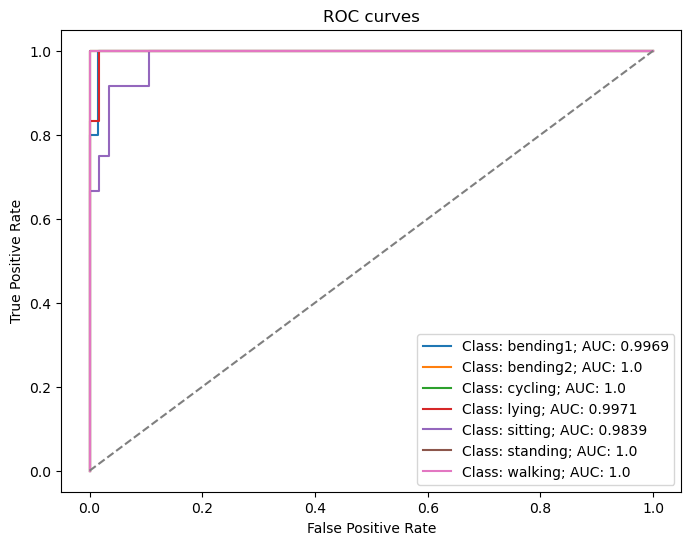

ROC Curve for Test Data


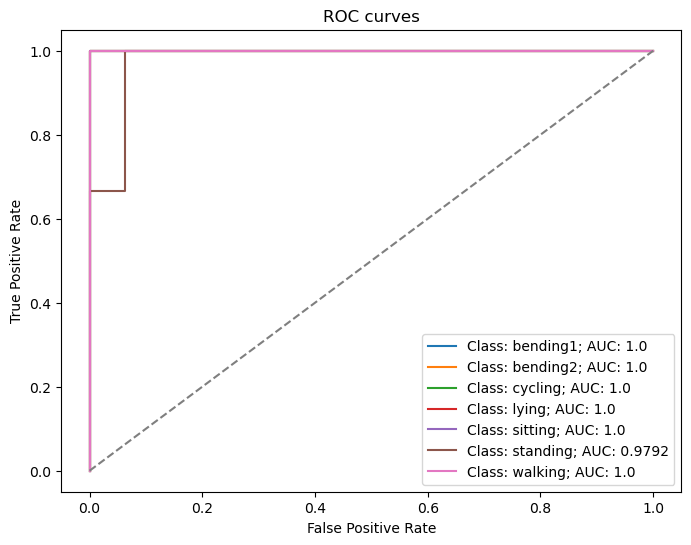

In [37]:
print("Best model with split = {}, max_test_accuracy = {}\n".format(best_split, max_test_accuracy))
logistic_regression_classification(train_data_map, test_data_map, best_split, is_plot_roc = True, features = selected_features)

#### 2.3.2 ii Naive Bayes

In [38]:
split_range, result = 20, []
max_test_accuracy, best_split = 0, 1

for split in range(1, split_range + 1):
    result.append(logistic_regression_classification(train_data_map, test_data_map, split, is_gaussian = True, features = selected_features))
    if result[-1][1] > max_test_accuracy:
        max_test_accuracy = result[-1][1]
        best_split = split

result = pd.DataFrame(result, columns = ['L', 'Train Score', 'Train Error'])
result

,L,Train Score,Train Error
0,1,0.813187,0.1868
1,2,0.841758,0.1582
2,3,0.781319,0.2187
3,4,0.797802,0.2022
4,5,0.796703,0.2033
5,6,0.783516,0.2165
6,7,0.839560,0.1604
7,8,0.754945,0.2451
8,9,0.769231,0.2308
9,10,0.812088,0.1879


Best model with split = 2, max_test_accuracy = 0.8417582417582418

Confusion matrix for test data:
[[0 0 0 0 2 0 0]
 [0 1 0 0 1 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 2 1 0]
 [0 0 0 0 2 1 0]
 [0 0 0 0 0 0 3]]
ROC Curve for Train Data


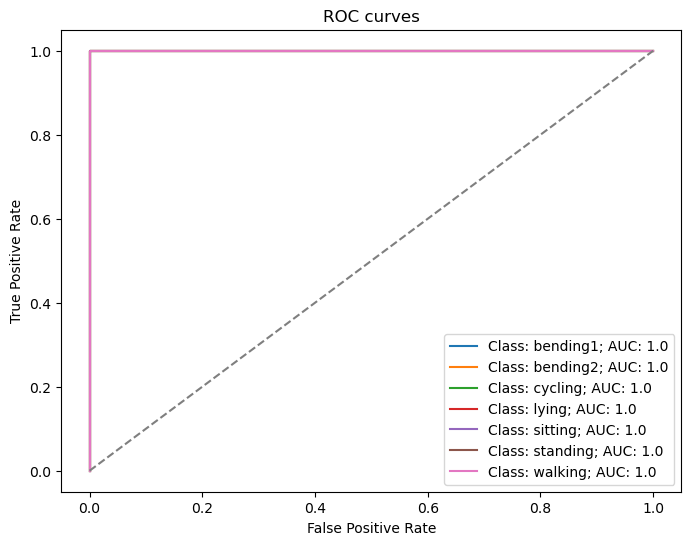

ROC Curve for Test Data


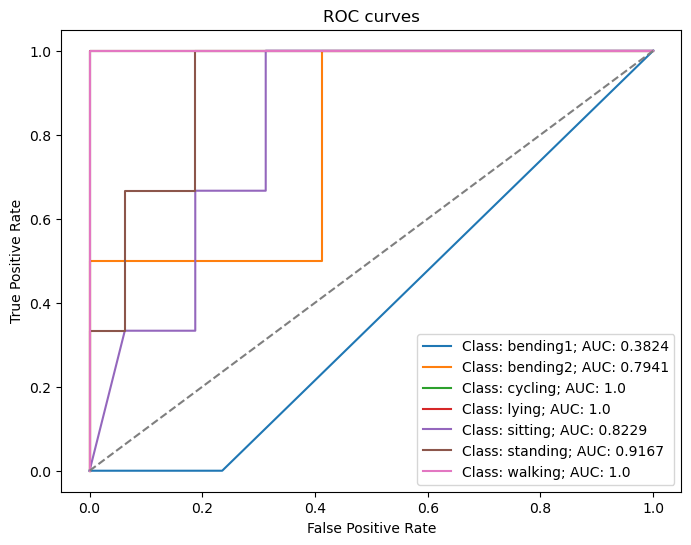

In [39]:
print("Best model with split = {}, max_test_accuracy = {}\n".format(best_split, max_test_accuracy))
logistic_regression_classification(train_data_map, test_data_map, best_split, is_gaussian = True, is_plot_roc = True, features = selected_features)

In [40]:
split_range, result = 20, []
max_test_accuracy, best_split = 0, 1

for split in range(1, split_range + 1):
    result.append(logistic_regression_classification(train_data_map, test_data_map, split, is_multinomial_prior = True, features = selected_features))
    if result[-1][1] > max_test_accuracy:
        max_test_accuracy = result[-1][1]
        best_split = split

result = pd.DataFrame(result, columns = ['L', 'Train Score', 'Train Error'])
result

,L,Train Score,Train Error
0,1,0.839560,0.1604
1,2,0.854945,0.1451
2,3,0.840659,0.1593
3,4,0.854945,0.1451
4,5,0.854945,0.1451
5,6,0.854945,0.1451
6,7,0.840659,0.1593
7,8,0.826374,0.1736
8,9,0.783516,0.2165
9,10,0.826374,0.1736


Best model with split = 2, max_test_accuracy = 0.8549450549450549

Confusion matrix for test data:
[[2 0 0 0 0 0 0]
 [1 1 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 2 1 0]
 [0 0 0 0 1 2 0]
 [0 0 0 0 0 0 3]]
ROC Curve for Train Data


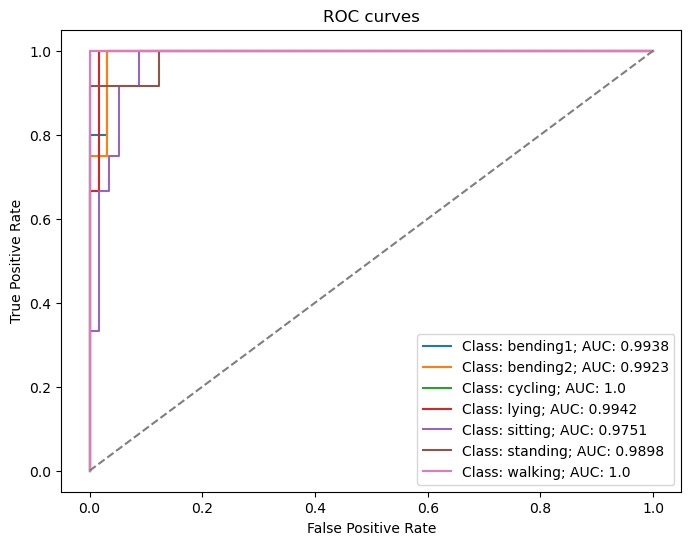

ROC Curve for Test Data


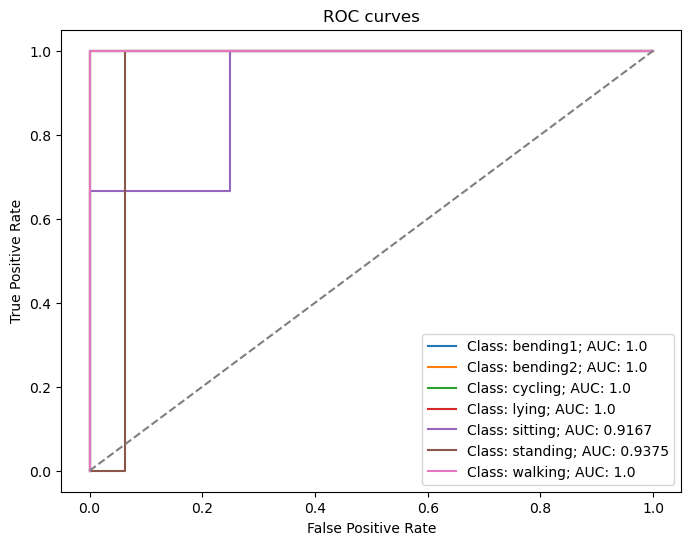

In [41]:
print("Best model with split = {}, max_test_accuracy = {}\n".format(best_split, max_test_accuracy))
logistic_regression_classification(train_data_map, test_data_map, best_split, is_multinomial_prior = True, is_plot_roc = True, features = selected_features)

#### 2.3.3 ii Comparison

* Within the Naive Bayes’ classifier the Multinomial prior (0.85 accuracy) performs better as compared to the Gaussian prior (0.84 accuracy).

#### 2.3.4 iii Best result

The area under the ROC curve (AUC) is relatively higher for the multinomial logistic regression model than for the Gaussian Naive Bayes and Multinomial Naive Bayes classifiers. Therefore, multinomial logistic regression provides the best overall classification performance for the given dataset.

## 3. ISLR 4.8.3

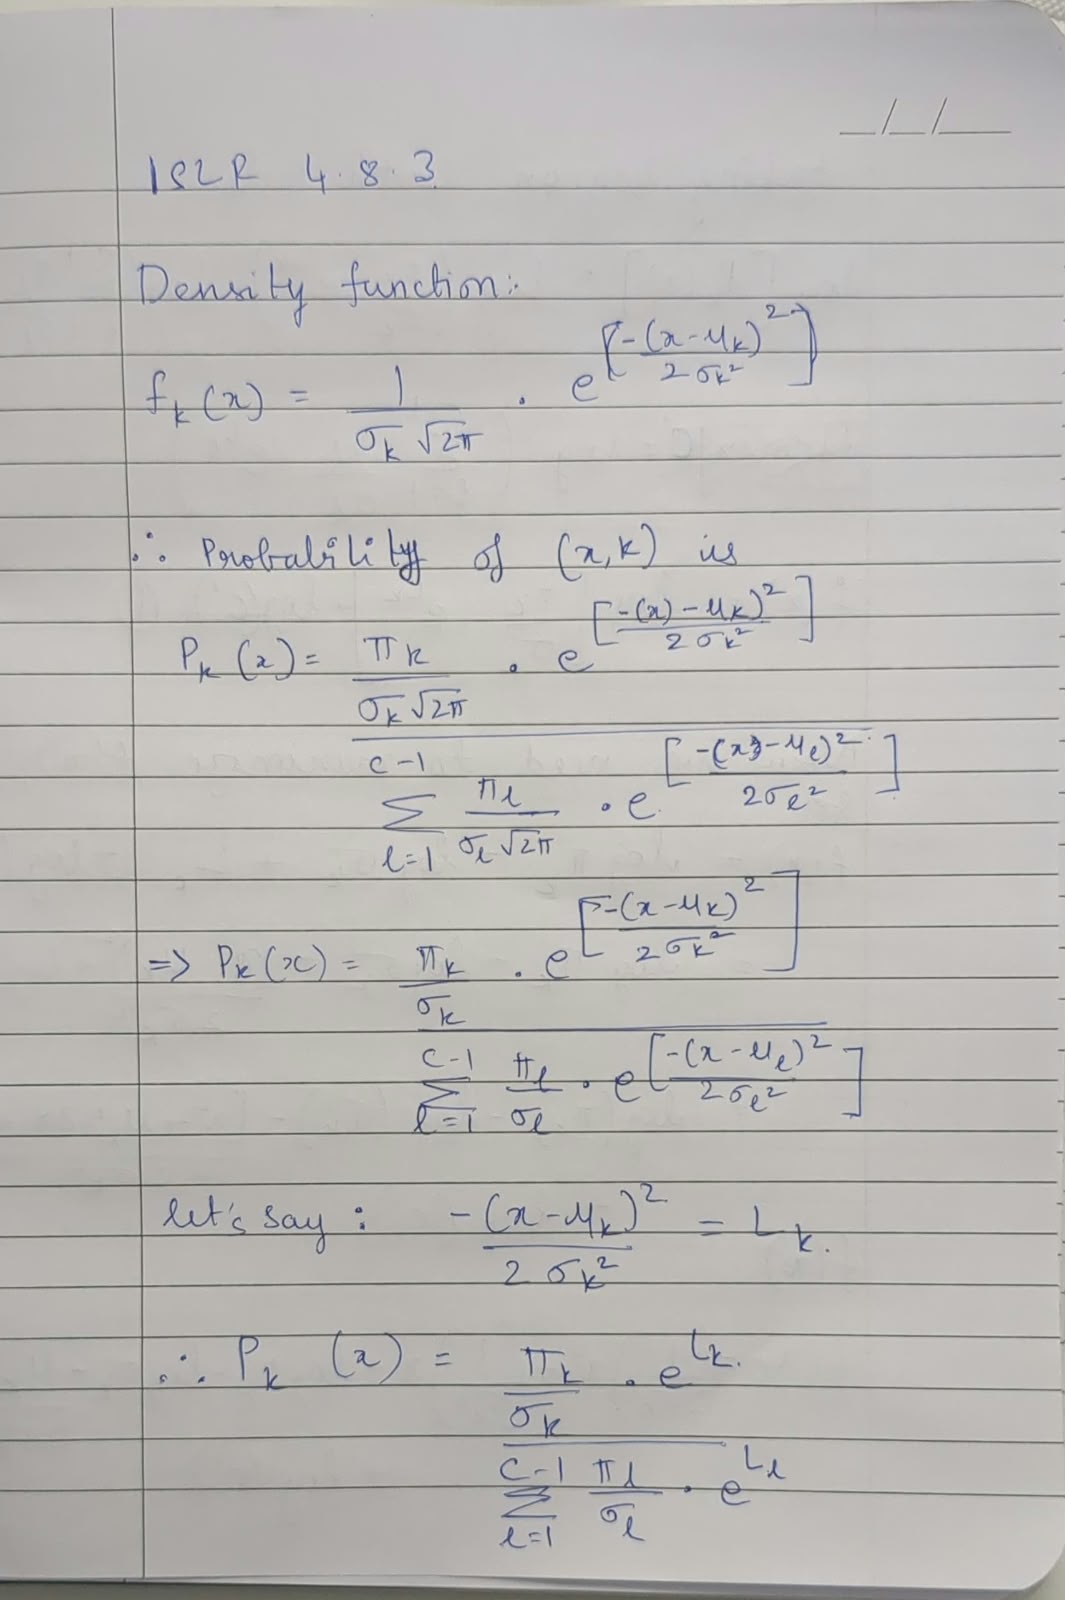

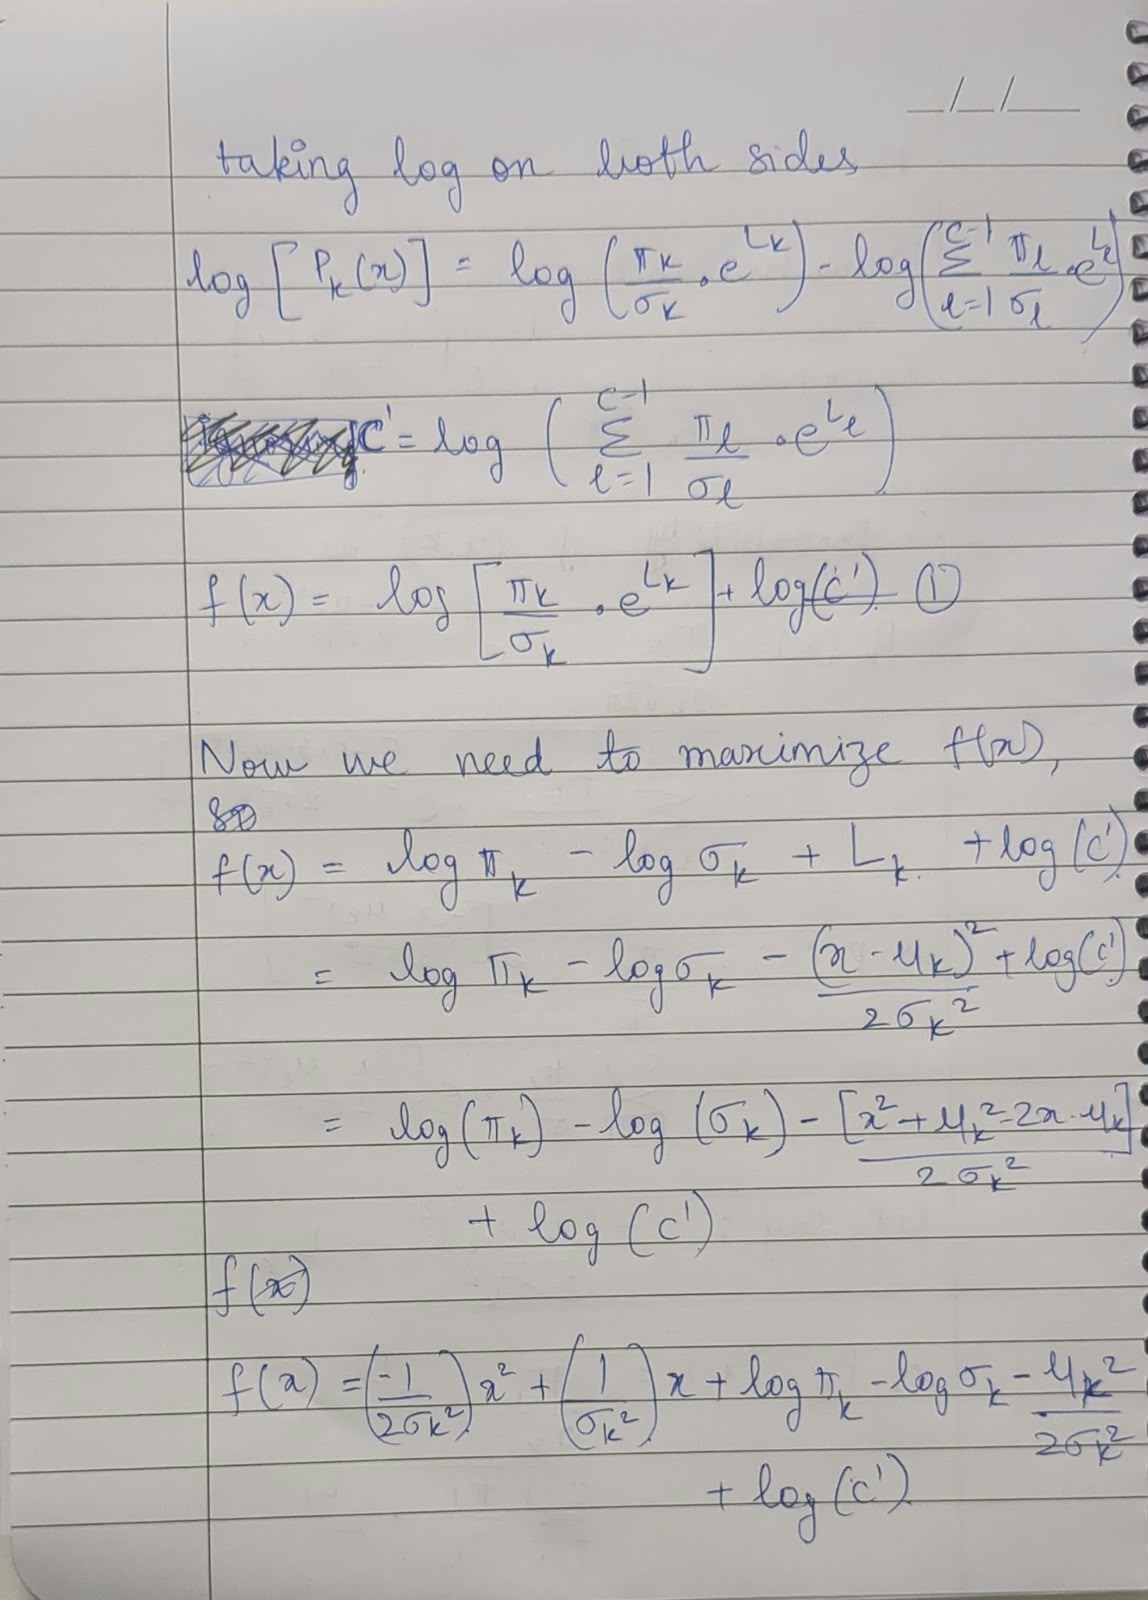

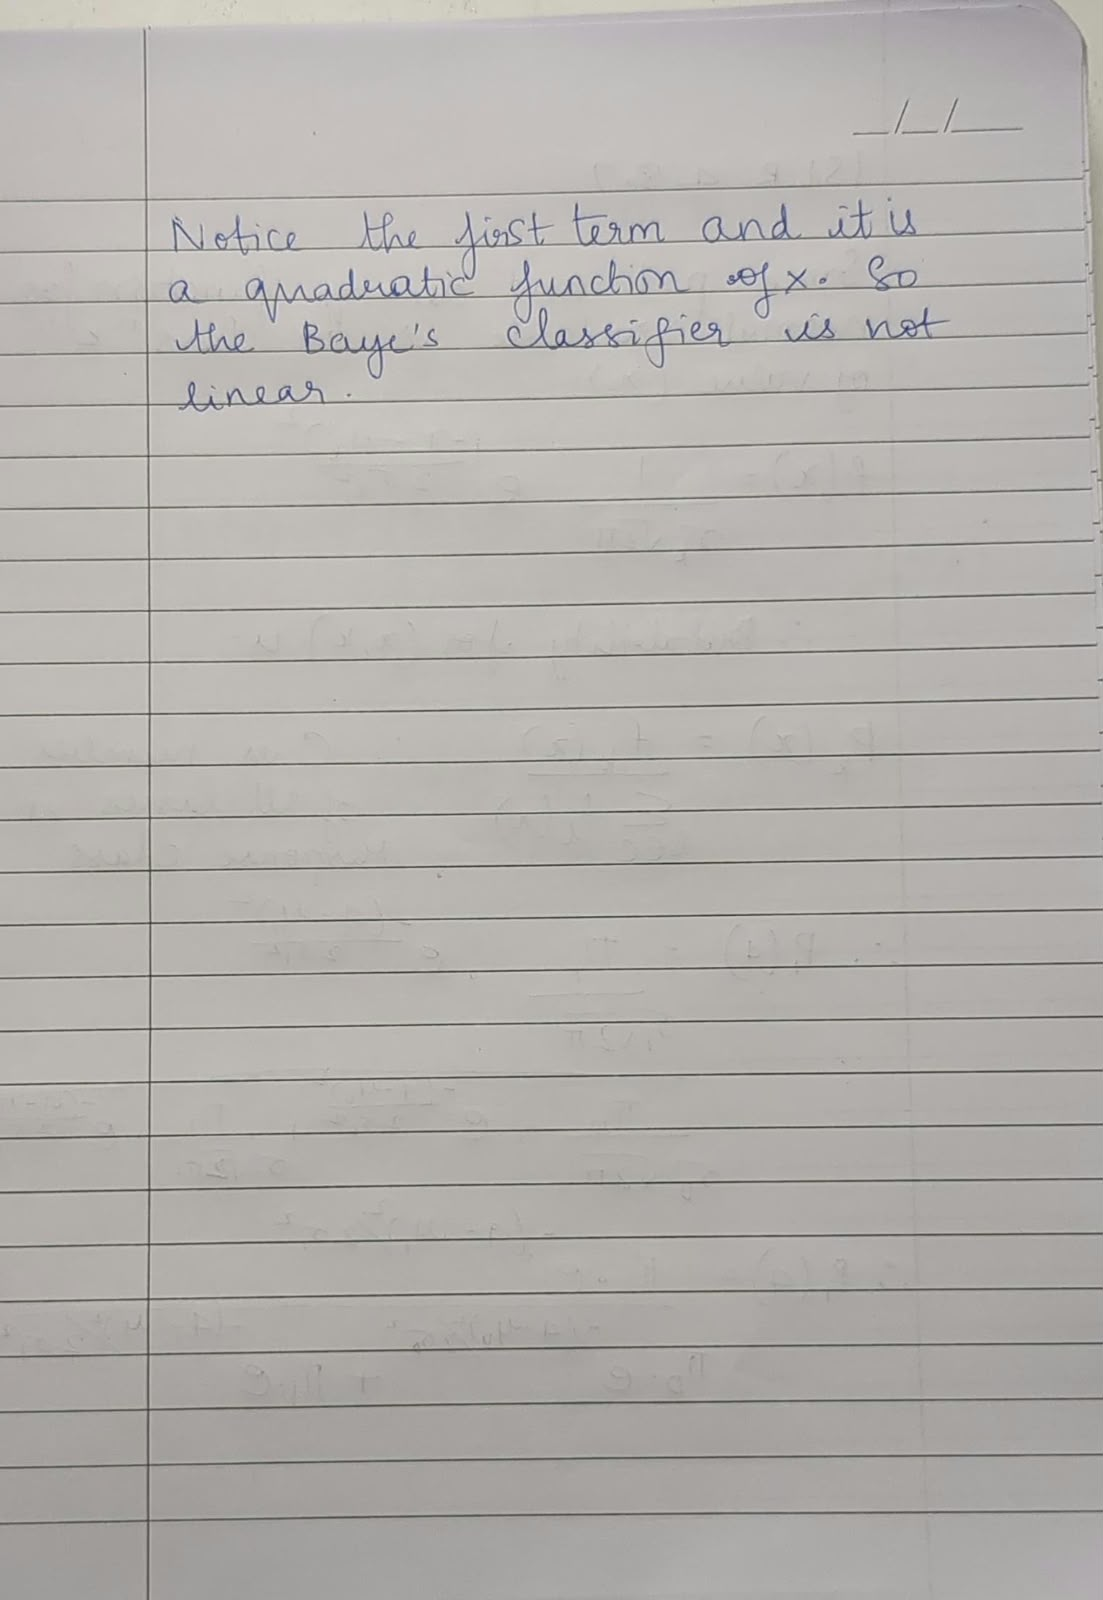




## 4. ISLR 4.8.7

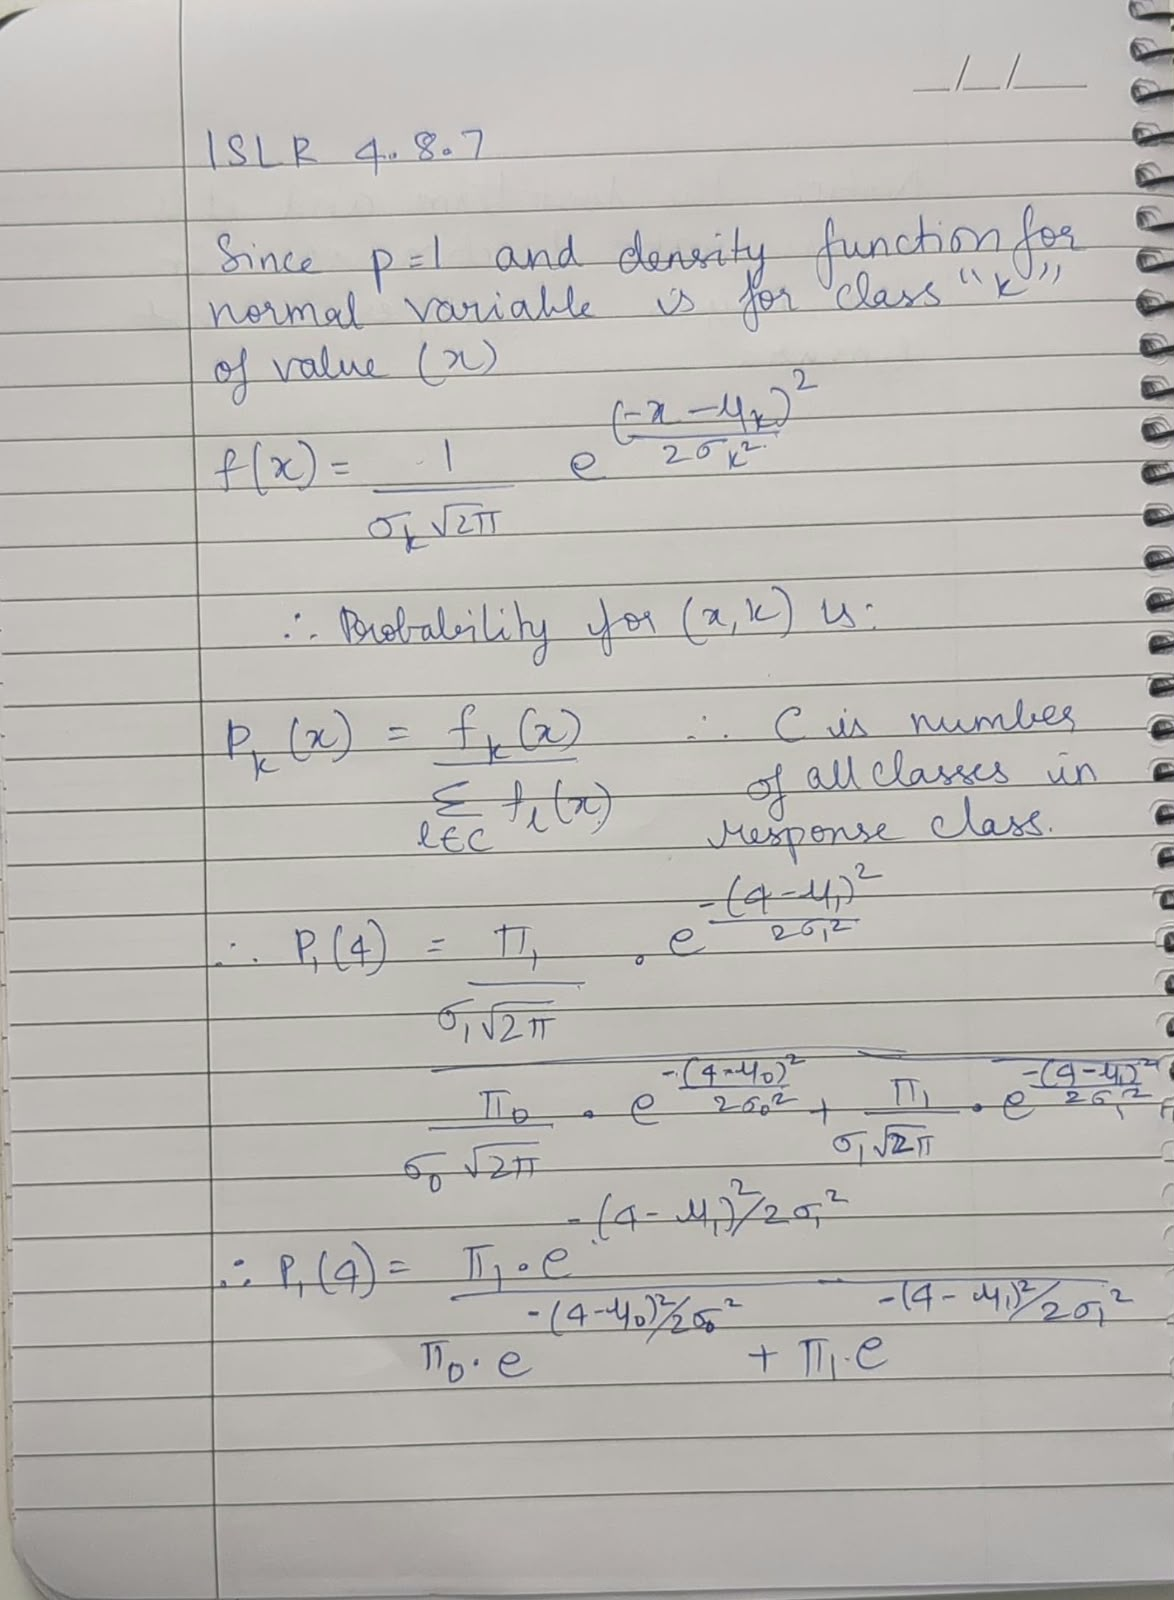

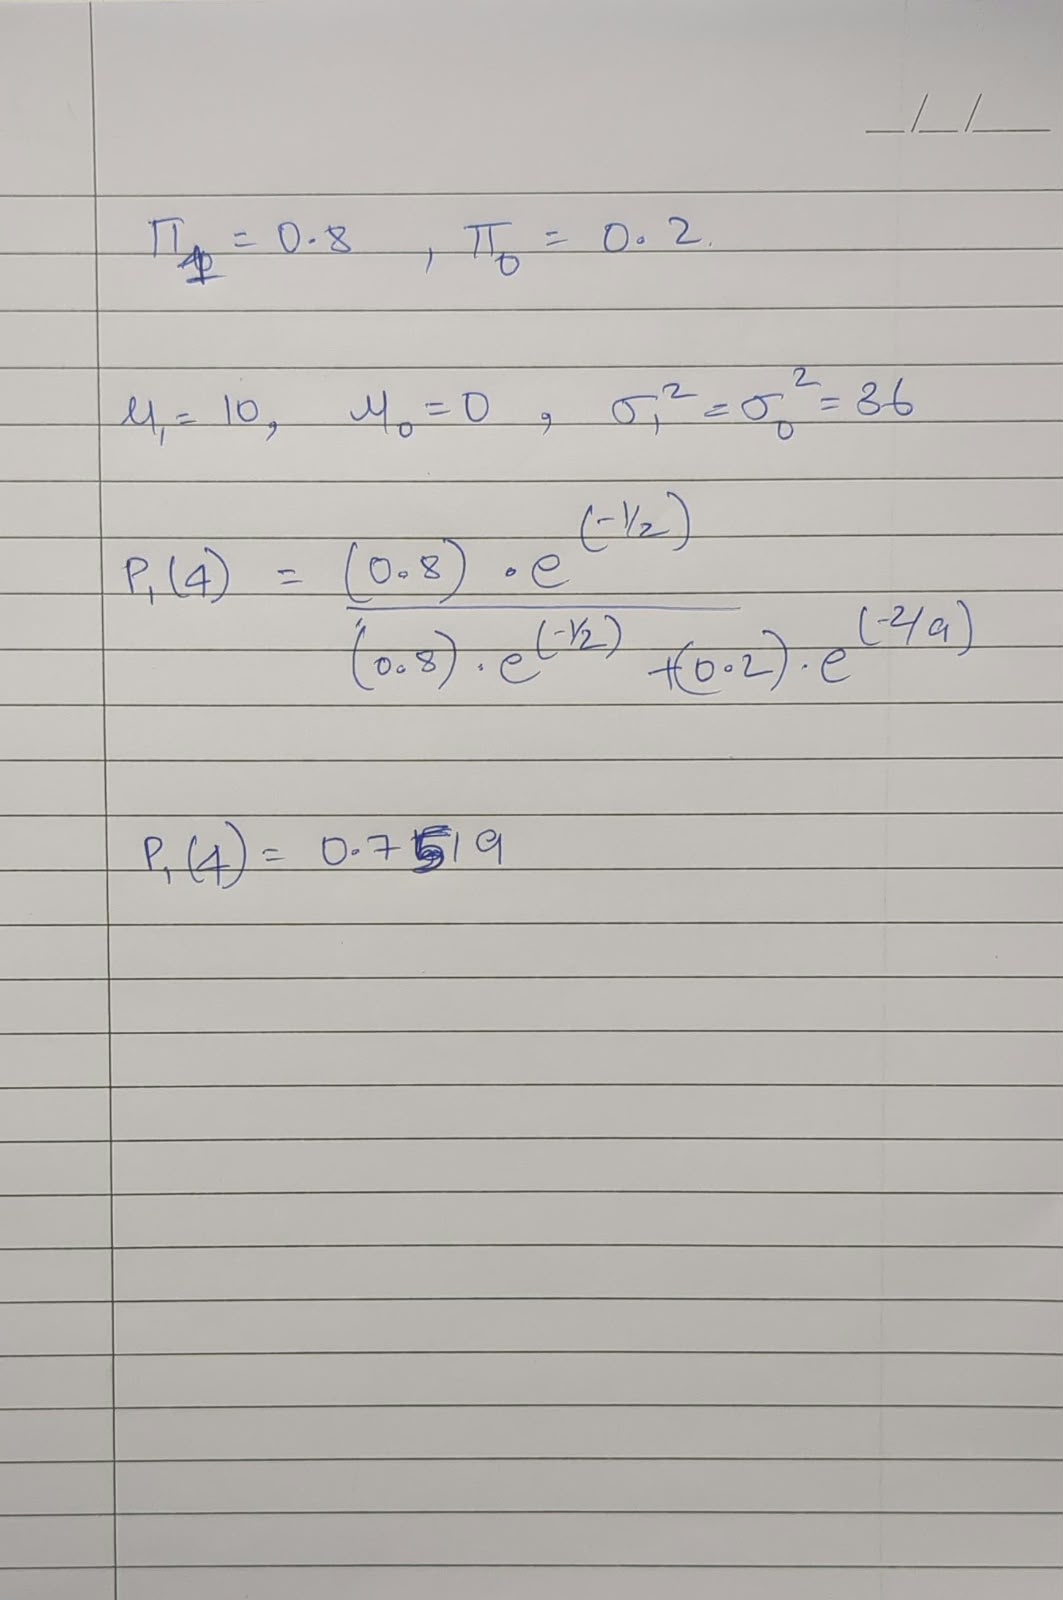